# Assessment 8: K-Means and Hierarchical Clustering
**School of Computer Science and Engineering** | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. R `kmeans/hclust/dist/cutree/scale` -> `sklearn.cluster.KMeans`, `scipy.cluster.hierarchy`, `StandardScaler`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Part A - K-Means Clustering
## 1-2. Load and view the dataset

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


In [3]:
print(df.info())
df.sample(10, random_state=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1525 entries, 0 to 1524
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   vote                     1525 non-null   object
 1   age                      1525 non-null   int64 
 2   economic_cond_national   1525 non-null   int64 
 3   economic_cond_household  1525 non-null   int64 
 4   Blair                    1525 non-null   int64 
 5   Hague                    1525 non-null   int64 
 6   Kennedy                  1525 non-null   int64 
 7   Europe                   1525 non-null   int64 
 8   political_knowledge      1525 non-null   int64 
 9   gender                   1525 non-null   object
dtypes: int64(8), object(2)
memory usage: 119.3+ KB
None


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
91,Conservative,49,1,1,2,4,3,8,3,female
1194,Labour,34,3,3,2,4,5,9,2,male
201,Liberal Democrat,51,2,2,4,4,4,4,2,male
613,Conservative,30,2,3,4,4,5,7,3,male
283,Liberal Democrat,42,3,3,2,2,4,9,0,male
181,Conservative,90,4,4,2,4,4,11,3,female
1230,Liberal Democrat,39,3,5,4,1,4,1,2,female
916,Labour,29,4,4,4,2,4,2,2,female
597,Conservative,50,3,2,2,2,2,3,2,male
807,Labour,77,4,4,5,2,4,5,2,male


## 3. Check missing values

In [4]:
print(df.isna().sum())
print("Total missing:", df.isna().sum().sum())
df = df.dropna().reset_index(drop=True)

vote                       0
age                        0
economic_cond_national     0
economic_cond_household    0
Blair                      0
Hague                      0
Kennedy                    0
Europe                     0
political_knowledge        0
gender                     0
dtype: int64
Total missing: 0


## 4. Distribution of the dependent variable (`vote`)

In [5]:
print(df["vote"].value_counts())
print()
print(df["vote"].value_counts(normalize=True).round(3))

vote
Labour              720
Conservative        462
Liberal Democrat    343
Name: count, dtype: int64

vote
Labour              0.472
Conservative        0.303
Liberal Democrat    0.225
Name: proportion, dtype: float64


## 5. Select only numerical features (others removed)

In [6]:
X = df.select_dtypes(include="number")
print("Features used:", X.columns.tolist(), "| shape:", X.shape)

Features used: ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge'] | shape: (1525, 8)


## 6. Standardize the data

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(X_scaled_df.describe().loc[["mean", "std"]].round(3))

,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 7. K-Means with 2 centres

In [8]:
km2 = KMeans(n_clusters=2, n_init=25, random_state=123)
km2.fit(X_scaled)

KMeans(n_clusters=2, n_init=25, random_state=123)

## 8. Display K-Means results

In [9]:
sizes = np.bincount(km2.labels_)
totss = (X_scaled ** 2).sum()               # total sum of squares (data is centred)
tot_withinss = km2.inertia_
betweenss = totss - tot_withinss

print("K-means clustering with 2 clusters of sizes:", sizes.tolist())
print("Iterations         :", km2.n_iter_)
print(f"Within-cluster SS  : {tot_withinss:.2f}")
print(f"Between-cluster SS : {betweenss:.2f}")
print(f"Total SS           : {totss:.2f}")
print(f"(between_SS / total_SS) = {100 * betweenss / totss:.1f} %")
print("\nCluster assignment (first 15):", km2.labels_[:15])

K-means clustering with 2 clusters of sizes: [860, 665]
Iterations         : 7
Within-cluster SS  : 10124.08
Between-cluster SS : 2075.92
Total SS           : 12200.00
(between_SS / total_SS) = 17.0 %

Cluster assignment (first 15): [0 0 0 0 1 0 1 0 1 1 1 0 0 1 1]


## 9. Cluster centres (standardized scale)

In [10]:
centers = pd.DataFrame(km2.cluster_centers_, columns=X.columns).round(3)
centers.index.name = "cluster"
display(centers)

# centres in original units
display(pd.DataFrame(scaler.inverse_transform(km2.cluster_centers_), columns=X.columns).round(2))

,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
cluster,,,,,,,,
0,-0.063,0.471,0.387,0.559,-0.390,0.188,-0.422,0.006
1,0.082,-0.609,-0.500,-0.723,0.504,-0.243,0.545,-0.008


,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
0,53.19,3.66,3.50,3.99,2.27,3.34,5.34,1.55
1,55.47,2.71,2.68,2.49,3.37,2.87,8.53,1.53


## 10. WCSS for K = 1 to 10

In [11]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=123).fit(X_scaled)
    wcss.append(km.inertia_)
wcss_df = pd.DataFrame({"K": range(1, 11), "WCSS": np.round(wcss, 2)})
wcss_df

,K,WCSS
0,1,12200.00
1,2,10124.08
2,3,9086.87
3,4,8560.49
4,5,8103.55
5,6,7711.23
6,7,7386.15
7,8,7094.65
8,9,6828.62
9,10,6634.67


## 11. Elbow plot

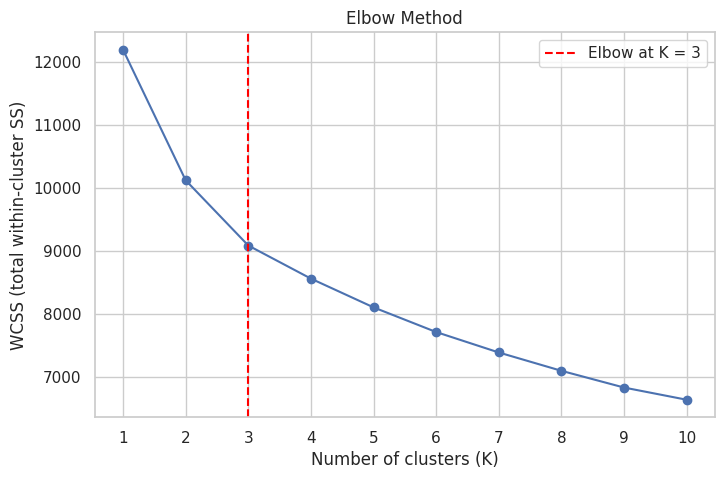

Elbow recommendation: K = 3


In [12]:
# automatic elbow = point farthest from the straight line joining first and last WCSS points
k_vals = np.arange(1, 11)
xn = (k_vals - k_vals.min()) / (k_vals.max() - k_vals.min())
yn = (np.array(wcss) - min(wcss)) / (max(wcss) - min(wcss))
dist = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0]) / \
       np.hypot(yn[-1] - yn[0], xn[-1] - xn[0])
k_opt = int(k_vals[np.argmax(dist)])

fig, ax = plt.subplots()
ax.plot(k_vals, wcss, "bo-")
ax.axvline(k_opt, color="red", linestyle="--", label=f"Elbow at K = {k_opt}")
ax.set(title="Elbow Method", xlabel="Number of clusters (K)", ylabel="WCSS (total within-cluster SS)",
       xticks=k_vals)
ax.legend()
plt.show()
print("Elbow recommendation: K =", k_opt)

## 12. K-Means with the elbow-recommended K

Cluster sizes:
 cluster
0    390
1    609
2    526
Name: count, dtype: int64

Cluster centres (original units):


,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
0,54.34,3.50,3.37,3.68,2.53,3.21,7.12,0.05
1,52.11,3.60,3.39,3.95,2.20,3.38,4.66,2.27
2,56.47,2.64,2.68,2.36,3.55,2.80,8.83,1.81


Clusters vs actual vote:


vote,Conservative,Labour,Liberal Democrat
cluster,,,
0,55,257,78
1,56,382,171
2,351,81,94


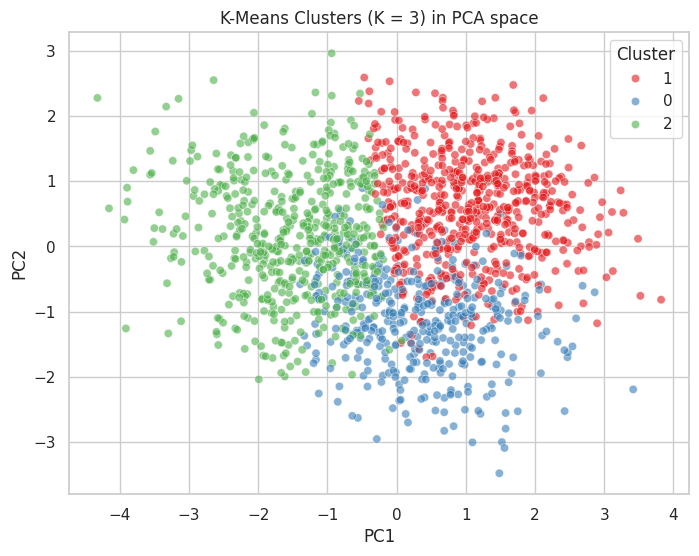

In [13]:
km_final = KMeans(n_clusters=k_opt, n_init=25, random_state=123).fit(X_scaled)
df["cluster"] = km_final.labels_

print("Cluster sizes:\n", df["cluster"].value_counts().sort_index())
print("\nCluster centres (original units):")
display(pd.DataFrame(scaler.inverse_transform(km_final.cluster_centers_), columns=X.columns).round(2))

print("Clusters vs actual vote:")
display(pd.crosstab(df["cluster"], df["vote"]))

# visualise clusters in 2-D using the first two principal components
pcs = PCA(n_components=2).fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["cluster"].astype(str), palette="Set1", alpha=0.6, ax=ax)
ax.set(title=f"K-Means Clusters (K = {k_opt}) in PCA space", xlabel="PC1", ylabel="PC2")
ax.legend(title="Cluster")
plt.show()

# Part B - Hierarchical Clustering
## 1-2. Load and view the dataset

In [14]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


## 3. Check missing values

In [15]:
print("Total missing:", df.isna().sum().sum())
df = df.dropna().reset_index(drop=True)

Total missing: 0


## 4-5. Select numerical attributes and standardize

In [16]:
X = df.select_dtypes(include="number")
X_scaled = StandardScaler().fit_transform(X)
print(X.columns.tolist(), X_scaled.shape)

['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge'] (1525, 8)


## 6. Euclidean distance

In [17]:
d = pdist(X_scaled, metric="euclidean")          # condensed distance matrix
print("Number of pairwise distances:", d.shape[0])
print("First 5 distances:", np.round(d[:5], 3))

Number of pairwise distances: 1162050
First 5 distances: [3.069 2.245 3.383 3.234 3.31 ]


## 7. Hierarchical clustering - Ward's method (R `hclust(method='ward.D2')`)

In [18]:
Z = linkage(d, method="ward")
print("Linkage matrix shape:", Z.shape, "(columns: cluster_a, cluster_b, distance, size)")
print(Z[-5:].round(3))

Linkage matrix shape: (1524, 4) (columns: cluster_a, cluster_b, distance, size)
[[3036.    3043.      26.568  451.   ]
 [3039.    3042.      28.426  479.   ]
 [3037.    3041.      35.301  595.   ]
 [3044.    3045.      49.978  930.   ]
 [3046.    3047.      50.937 1525.   ]]


## 8. Dendrogram


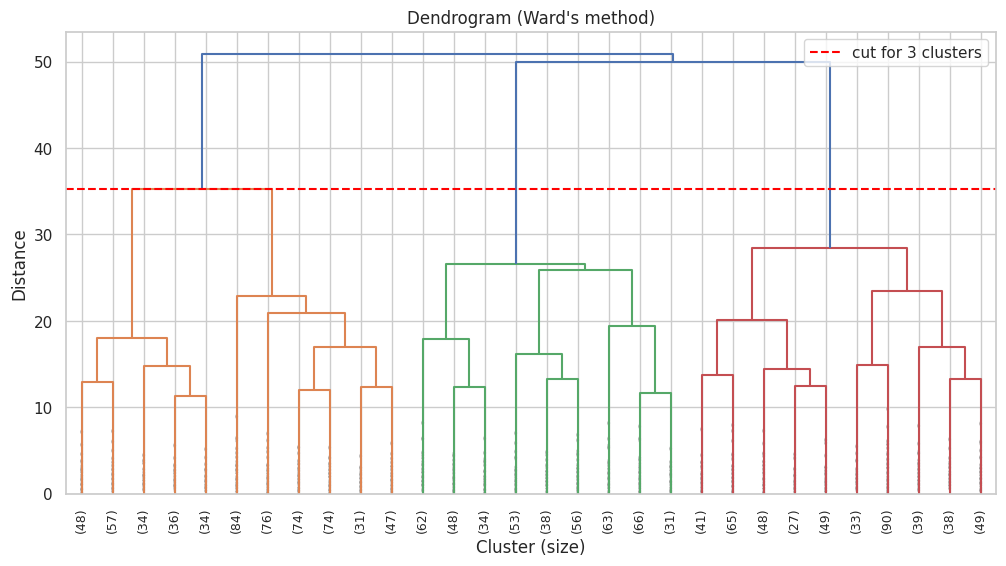

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, ax=ax)
ax.axhline(y=Z[-3, 2] - 1e-6, color="red", linestyle="--", label="cut for 3 clusters")
ax.set(title="Dendrogram (Ward's method)", xlabel="Cluster (size)", ylabel="Distance")
ax.legend()
plt.show()

## 9. Divide into 3 clusters and display cluster assignments

In [20]:
clusters = fcluster(Z, t=3, criterion="maxclust")
df["hc_cluster"] = clusters
print("Cluster assignments (first 30):", clusters[:30])
df[["vote", "hc_cluster"]].head(10)

Cluster assignments (first 30): [1 1 1 3 2 1 1 3 3 2 3 1 1 3 2 3 3 1 3 2 3 2 2 1 3 3 2 1 1 1]


,vote,hc_cluster
0,Liberal Democrat,1
1,Labour,1
2,Labour,1
3,Labour,3
4,Labour,2
5,Labour,1
6,Liberal Democrat,1
7,Labour,3
8,Labour,3
9,Labour,2


## 10. Number of samples in each cluster

In [21]:
print(pd.Series(clusters).value_counts().sort_index().rename_axis("cluster").rename("n_samples"))
print()
display(pd.crosstab(df["hc_cluster"], df["vote"]))

cluster
1    595
2    451
3    479
Name: n_samples, dtype: int64



vote,Conservative,Labour,Liberal Democrat
hc_cluster,,,
1,107,346,142
2,255,99,97
3,100,275,104
